# Analysis on saved results.

| Setting | GAN universal | Sinusoidal baseline |
|---|---|---|
| Dataset | CIFAR-10 | CIFAR-10 |
| Source → target | Truck (9) → deer (4) | Truck (9) → deer (4) |
| User model | ResNet-32 (`r32p`) | ResNet-32 (`r32p`) |
| Label flips | 1,500 | 1,500 |
| Trigger | Learned universal noise (`1xg`) | Fixed sinusoid (`1xs`) |
| Trigger strength | Maximum pixel change 6/255 | Strength parameter 6 (check actual pixel differences) |

The sinusoidal configuration was constructed from the GAN experiment configuration with only the trigger and output paths changed. Both are single runs; small differences should not be interpreted as statistically significant.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

start = Path.cwd().resolve()
ROOT = next((p for p in [start, *start.parents] if (p / 'run_experiment.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Cannot locate FLIP repository. Open the notebook from FLIP/ or FLIP/notebooks/.')
print('FLIP root:', ROOT)

FOLDERS = {
    'GAN universal (1xg)': ROOT / 'experiments/gan_universal_user',
    'Sinusoidal (1xs)': ROOT / 'experiments/sinusoidal_baseline_user',
}
results = {}
for name, folder in FOLDERS.items():
    clean_path, poison_path = folder / 'caccs.npy', folder / 'paccs.npy'
    if not clean_path.is_file() or not poison_path.is_file():
        raise FileNotFoundError(f'Missing results for {name}: {clean_path}, {poison_path}')
    clean, poison = np.load(clean_path), np.load(poison_path)
    if clean.ndim != 2 or poison.ndim != 2 or clean.shape[1] < 2 or poison.shape[1] < 2:
        raise ValueError(f'Unexpected metrics array shape for {name}: {clean.shape} / {poison.shape}')
    results[name] = dict(cta=clean[:, 0] * 100, pta=poison[:, 0] * 100,
                         clean_loss=clean[:, 1], poison_loss=poison[:, 1])
    print(f'{name}: {len(clean)} evaluation epochs loaded')

FLIP root: /users/eleves-b/2026/beatrice.camera/projects/FLIP
GAN universal (1xg): 200 evaluation epochs loaded
Sinusoidal (1xs): 200 evaluation epochs loaded


## 1. Final user-model results

- **CTA (Clean Test Accuracy)** evaluates normal classification on the clean CIFAR-10 test set.
- **PTA (Poison Test Accuracy)** evaluates the triggered source-class test samples against the poisoner's target label (truck → deer), provided the `LabelPoisoner` is used as configured.

In [2]:
summary = pd.DataFrame([
    {'Trigger': name,
     'CTA (%)': round(float(v['cta'][-1]), 2),
     'PTA (%)': round(float(v['pta'][-1]), 2),
     'Label flips': 1500,
     'Evaluation epochs': len(v['cta'])}
    for name, v in results.items()
])
display(summary)

baseline = results['Sinusoidal (1xs)']
gan = results['GAN universal (1xg)']
print(f"GAN minus sinusoidal: CTA = {gan['cta'][-1] - baseline['cta'][-1]:+.2f} pp; "
      f"PTA = {gan['pta'][-1] - baseline['pta'][-1]:+.2f} pp")

,Trigger,CTA (%),PTA (%),Label flips,Evaluation epochs
0,GAN universal (1xg),89.65,99.9,1500,200
1,Sinusoidal (1xs),89.77,99.8,1500,200


GAN minus sinusoidal: CTA = -0.12 pp; PTA = +0.10 pp


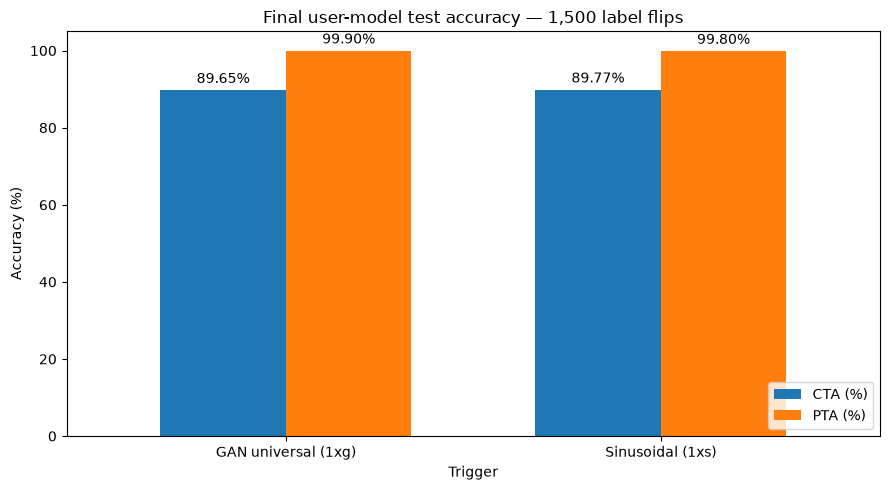

In [3]:
ax = summary.set_index('Trigger')[['CTA (%)','PTA (%)']].plot.bar(rot=0, figsize=(9, 5), width=0.67)
ax.set_title('Final user-model test accuracy — 1,500 label flips')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 105)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f%%', padding=3)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 2. Zero-flip control: adversarial transfer vs label poisoning

To determine whether the high attack success rate is caused by FLIP's label poisoning or by the trigger itself, we evaluate both methods with **0 and 1,500 flipped labels**. At 0 flips, the user model is trained on the original CIFAR-10 labels, without any label poisoning.

This comparison helps us investigate whether the GAN-generated trigger transfers to an independently trained clean model.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

experiments = {
    "Original FLIP — Sinusoidal": {
        0: "zero_flips_sinusoidal",
        1500: "sinusoidal_baseline_user"
    },
    "GAN Universal": {
        0: "zero_flips_gan",
        1500: "gan_universal_user"
    }
}

rows = []

for method, budgets in experiments.items():
    for flips, folder in budgets.items():
        path = ROOT / "experiments" / folder
        cta = np.load(path / "caccs.npy")[-1, 0] * 100
        pta = np.load(path / "paccs.npy")[-1, 0] * 100
        rows.append({"Method": method, "Label flips": flips, "CTA (%)": cta, "PTA (%)": pta})

df_zero = pd.DataFrame(rows)
display(df_zero.round(2))

,Method,Label flips,CTA (%),PTA (%)
0,Original FLIP — Sinusoidal,0,92.61,0.0
1,Original FLIP — Sinusoidal,1500,89.77,99.8
2,GAN Universal,0,92.63,1.5
3,GAN Universal,1500,89.65,99.9


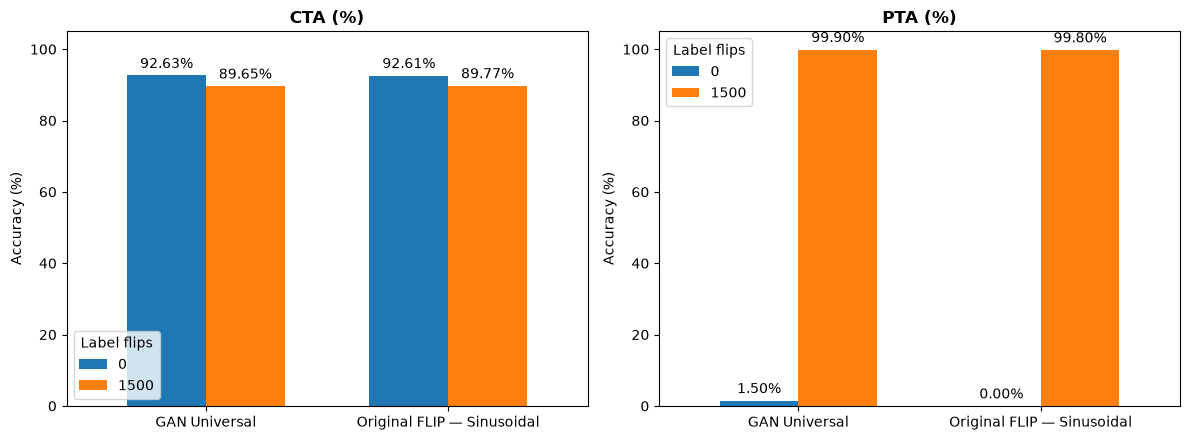

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, metric in zip(axes, ["CTA (%)", "PTA (%)"]):
    data = df_zero.pivot(index="Method", columns="Label flips", values=metric)
    data[[0, 1500]].plot(kind="bar", ax=ax, rot=0, width=0.65)
    ax.set_title(metric, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Accuracy (%)")
    ax.set_ylim(0, 105)
    ax.legend(title="Label flips")
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

In [15]:
comparison = df_zero.pivot(index="Method", columns="Label flips", values="PTA (%)")

comparison["Increase (pp)"] = comparison[1500] - comparison[0]
comparison.columns = ["PTA — 0 flips", "PTA — 1500 flips", "Increase (pp)"]

display(comparison.round(2))

,PTA — 0 flips,PTA — 1500 flips,Increase (pp)
Method,,,
GAN Universal,1.5,99.9,98.4
Original FLIP — Sinusoidal,0.0,99.8,99.8


## 3. Learning curves


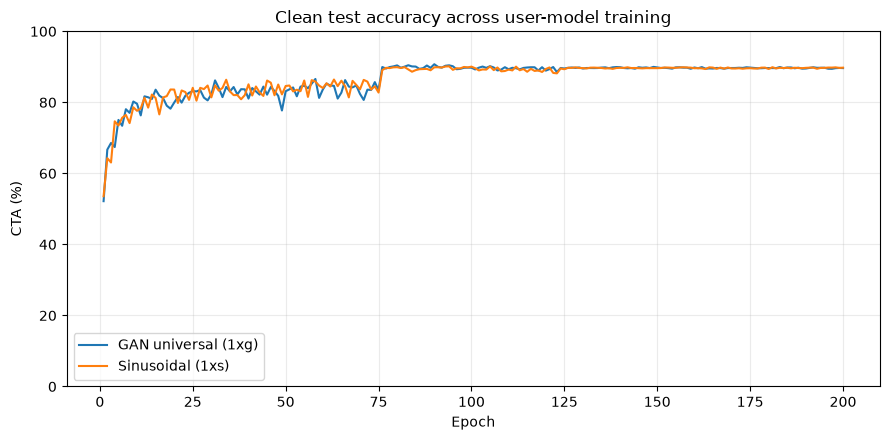

In [4]:
plt.figure(figsize=(9, 4.5))
for name, values in results.items():
    epochs = np.arange(1, len(values['cta']) + 1)
    plt.plot(epochs, values['cta'], label=name)
plt.title('Clean test accuracy across user-model training')
plt.xlabel('Epoch')
plt.ylabel('CTA (%)')
plt.ylim(0, 100)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

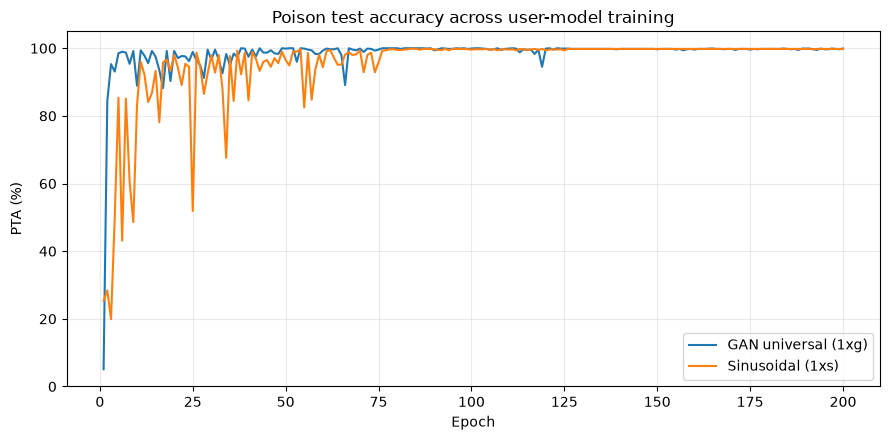

In [5]:
plt.figure(figsize=(9, 4.5))
for name, values in results.items():
    epochs = np.arange(1, len(values['pta']) + 1)
    plt.plot(epochs, values['pta'], label=name)
plt.title('Poison test accuracy across user-model training')
plt.xlabel('Epoch')
plt.ylabel('PTA (%)')
plt.ylim(0, 105)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## 4. What do the triggers look like?

The following expert results were printed by `run_experiment.py` in the two runs. They describe **backdoored experts**, not the final label-only user models.

| Expert model | Clean test accuracy | Poison test accuracy |
|---|---:|---:|
| GAN universal | 83.59% | 100.00% |
| Sinusoidal | 84.85% | 99.10% |

These values should **not** be substituted for the user-model results in Section 1.

Original FLIP — Sinusoidal (1xs): L∞ = 6/255, RMS = 4.08/255
GAN Universal (1xg): L∞ = 6/255, RMS = 5.92/255


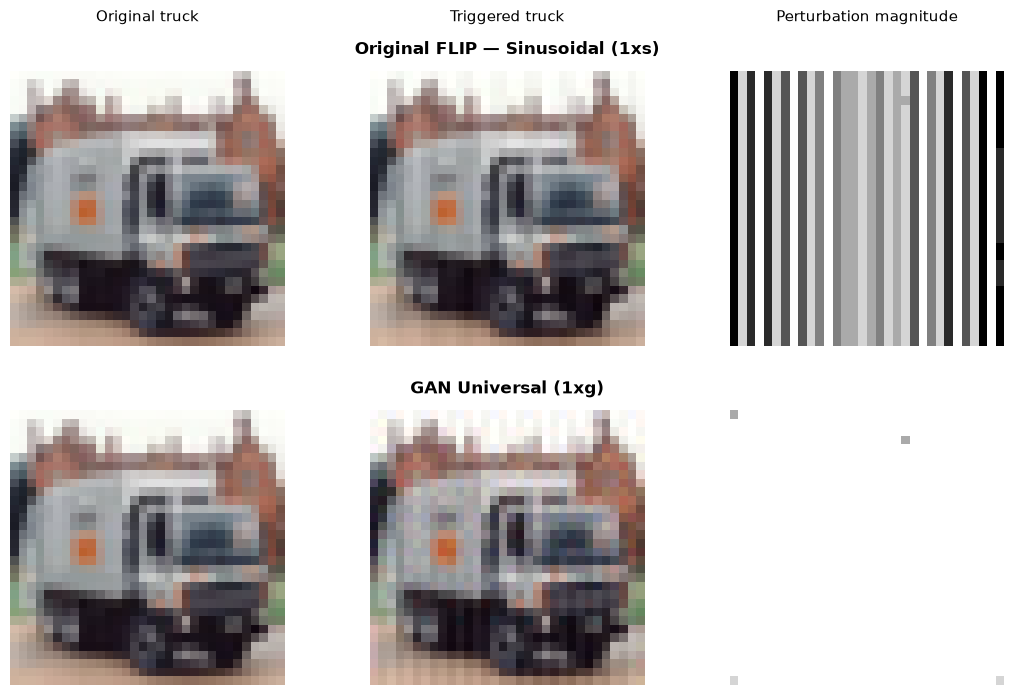

In [9]:
import sys
sys.path.insert(0, str(ROOT))

from torchvision.datasets import CIFAR10
from modules.base_utils.datasets import pick_poisoner

cifar = CIFAR10(root=str(ROOT / "data/data_cifar10"), train=False, download=False)
i = cifar.targets.index(9)
clean, y = cifar[i]
clean_px = np.asarray(clean, dtype=float)

def trigger(flag):
    return pick_poisoner(flag, "cifar", 4)((clean, y))[0]

methods = {
    "Original FLIP — Sinusoidal (1xs)": trigger("1xs"),
    "GAN Universal (1xg)": trigger("1xg")
}

fig, axes = plt.subplots(2, 3, figsize=(11, 7))

for row, (name, img) in enumerate(methods.items()):
    delta = np.asarray(img, dtype=float) - clean_px
    axes[row, 0].imshow(clean)
    axes[row, 1].imshow(img)
    axes[row, 2].imshow(np.abs(delta).max(axis=2), cmap="gray", vmin=0, vmax=6)

    axes[row, 1].set_title(name, fontweight="bold", fontsize=12, pad=12)
    for ax in axes[row]:
        ax.axis("off")

    print(f"{name}: L∞ = {np.abs(delta).max():.0f}/255, RMS = {np.sqrt(np.mean(delta**2)):.2f}/255")

for ax, title in zip(axes[0], ["Original truck", "Triggered truck", "Perturbation magnitude"]):
    ax.text(0.5, 1.18, title, transform=ax.transAxes,
            ha="center", fontsize=11)

plt.tight_layout(h_pad=2.5)
plt.show()

## 5. Expert comparison (reference)

Before generating the poisoned labels, FLIP trains a backdoored expert model for each trigger.

| Metric | Original FLIP — Sinusoidal (1xs) | GAN Universal (1xg) |
|---|---:|---:|
| Clean Test Accuracy (CTA) | 84.85% | 83.59% |
| Poison Test Accuracy (PTA) | 99.10% | 100.00% |

Both expert models achieve very high poison accuracy, indicating that both triggers are effective at this stage.

However, these results refer to the **expert models**, not the final user models trained with FLIP-generated labels. They are included for reference and should not be interpreted as the final label-only attack performance.

## 6. Lower poisoning budgets, extension


In [7]:
budgets = [150, 300, 500, 1000, 1500]
rows = []
for trigger, prefix, final_folder in [
    ('GAN universal (1xg)', 'gan_universal_user', FOLDERS['GAN universal (1xg)']),
    ('Sinusoidal (1xs)', 'sinusoidal_baseline_user', FOLDERS['Sinusoidal (1xs)']),
]:
    for budget in budgets:
        folder = final_folder if budget == 1500 else ROOT / f'experiments/{prefix}_{budget}'
        cfile, pfile = folder / 'caccs.npy', folder / 'paccs.npy'
        if not (cfile.is_file() and pfile.is_file()):
            continue
        rows.append({'Trigger': trigger, 'Label flips': budget,
                     'CTA (%)': np.load(cfile)[-1, 0] * 100,
                     'PTA (%)': np.load(pfile)[-1, 0] * 100})
budget_df = pd.DataFrame(rows)
display(budget_df.round(2))
if budget_df['Label flips'].nunique() > 1:
    plt.figure(figsize=(8, 4.5))
    for name, group in budget_df.groupby('Trigger'):
        group = group.sort_values('Label flips')
        plt.plot(group['Label flips'], group['PTA (%)'], marker='o', label=name)
    plt.xlabel('Flipped labels')
    plt.ylabel('Final PTA (%)')
    plt.ylim(0, 105)
    plt.title('Backdoor success vs poisoning budget')
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Only the 1,500-flip experiments are currently available; run lower-budget user models to build this curve.')

,Trigger,Label flips,CTA (%),PTA (%)
0,GAN universal (1xg),1500,89.65,99.9
1,Sinusoidal (1xs),1500,89.77,99.8


Only the 1,500-flip experiments are currently available; run lower-budget user models to build this curve.


## Summary of the Results

We investigated whether FLIP's original sinusoidal trigger could be replaced with a GAN-generated universal perturbation, keeping the same maximum perturbation bound ($L_\infty \leq 6/255$). The GAN was trained to generate noise that pushes a frozen ResNet-32 toward the target class while remaining difficult for a discriminator to distinguish from clean images.

Observations:
1. The GAN trigger achieves comparable attack success to the original sinusoidal trigger: with 1,500 flipped labels, both methods reach almost perfect PTA and a similar CTA. 
2. The zero-flip experiment confirms the importance of label poisoning (Without flipped labels, only 1.5% of triggered trucks are classified as deer).
3. Main difference = how quickly the victim model learns the backdoor (the GAN trigger achieves high poison accuracy within the first few epochs, the sinusoidal trigger becomes stable only after the learning-rate reduction)
4. The GAN did not successfully learn an imperceptible perturbation (the discriminator can distinguish triggered images from clean ones, RMS magnitude is also higher than that of the sinusoidal trigger).